# MSDS 565 — Project 3: Movie Genre Classification
## Notebook 1 — Exploratory Data Analysis


Before I start training anything, I want to understand what I'm working with. I'm looking at the movies, how often each genre shows up, and whether the plot descriptions have enough useful information to predict genre.

This notebook is EDA only. I'll handle vectorization and modeling in Notebook 2. One rule I'm keeping consistent throughout: **the plot synopsis is the only input to the classifiers.** Release year, runtime, ratings, and votes are here for exploration and filtering, not prediction.

### 1. Load the data

I'm using the `mpst_imdb_movies.csv` file provided for class. It already combines the plot synopses, IMDB genre labels, and movie metadata, so there's no reason to download or merge anything else. I'll keep the source CSV out of the GitHub repo, per the assignment.

In [1]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

DATA_PATH = next((path for path in [Path("mpst_imdb_movies.csv"), Path("../mpst_imdb_movies.csv"), Path("../../mpst_imdb_movies.csv"), Path("/mnt/data/mpst_imdb_movies.csv")] if path.exists()), Path("../../mpst_imdb_movies.csv"))
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Download mpst_imdb_movies.csv from class Drive "
        "and place it beside your project folder, or change DATA_PATH."
    )
df = pd.read_csv(DATA_PATH)
print(f"Movies: {len(df):,} | Columns: {len(df.columns)}")
display(df.head(3))

Movies: 11,824 | Columns: 33


,imdb_id,primaryTitle,plot_synopsis,synopsis_source,split,startYear,runtimeMinutes,averageRating,numVotes,Action,Adult,Adventure,Animation,Biography,Comedy,...,Family,Fantasy,Film-Noir,History,Horror,Music,Musical,Mystery,News,Romance,Sci-Fi,Sport,Thriller,War,Western
0,tt0057603,Black Sabbath,Note: this synopsis is for the orginal Italian...,imdb,train,1963.0,92.0,7.0,12895,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,tt0033045,The Shop Around the Corner,"Matuschek's, a gift store in Budapest, is the ...",imdb,test,1940.0,99.0,8.0,35221,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,tt0113862,Mr. Holland's Opus,"Glenn Holland, not a morning person by anyone'...",imdb,train,1995.0,143.0,7.3,40547,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0


### 2. Quick data check

First I'm checking the columns, missing values, and the provided train/validation/test splits. The genre labels are binary, but they aren't mutually exclusive. A movie can be Action and Comedy at the same time, which matters once I start building the classifiers.

In [2]:
metadata_cols = {
    "imdb_id", "primaryTitle", "plot_synopsis", "synopsis_source", "split",
    "startYear", "runtimeMinutes", "averageRating", "numVotes"
}
required = {"imdb_id", "plot_synopsis", "split", "startYear", "runtimeMinutes", "averageRating", "numVotes"}
missing = required - set(df.columns)
assert not missing, f"Missing required columns: {missing}"
genres = [c for c in df.columns if c not in metadata_cols and df[c].dropna().isin([0, 1]).all()]
assert genres, "No genre dummy columns found; check the provided CSV."
print(f"Genres ({len(genres)}):", ", ".join(genres))
print("Split sizes:")
display(df["split"].value_counts(dropna=False).rename_axis("split").to_frame("movies"))
print("Missingness in key columns:")
display(df[list(required)].isna().sum().rename("nulls").to_frame())

Genres (24): Action, Adult, Adventure, Animation, Biography, Comedy, Crime, Documentary, Drama, Family, Fantasy, Film-Noir, History, Horror, Music, Musical, Mystery, News, Romance, Sci-Fi, Sport, Thriller, War, Western
Split sizes:


,movies
split,
train,7596
test,2360
val,1868


Missingness in key columns:


,nulls
averageRating,0
runtimeMinutes,7
numVotes,0
imdb_id,0
plot_synopsis,0
split,0
startYear,1


### 3. Movie characteristics

I want a baseline picture of the dataset before making filtering decisions. I'm checking release year, runtime, IMDB rating, and vote count. Vote counts cover a wide range, so a log scale makes that distribution easier to read.

The median movie came out in **1995**, runs **100 minutes**, has an average rating of **6.5**, and has **10,858 votes**. These numbers help describe the dataset, but none of them will go into the genre models.

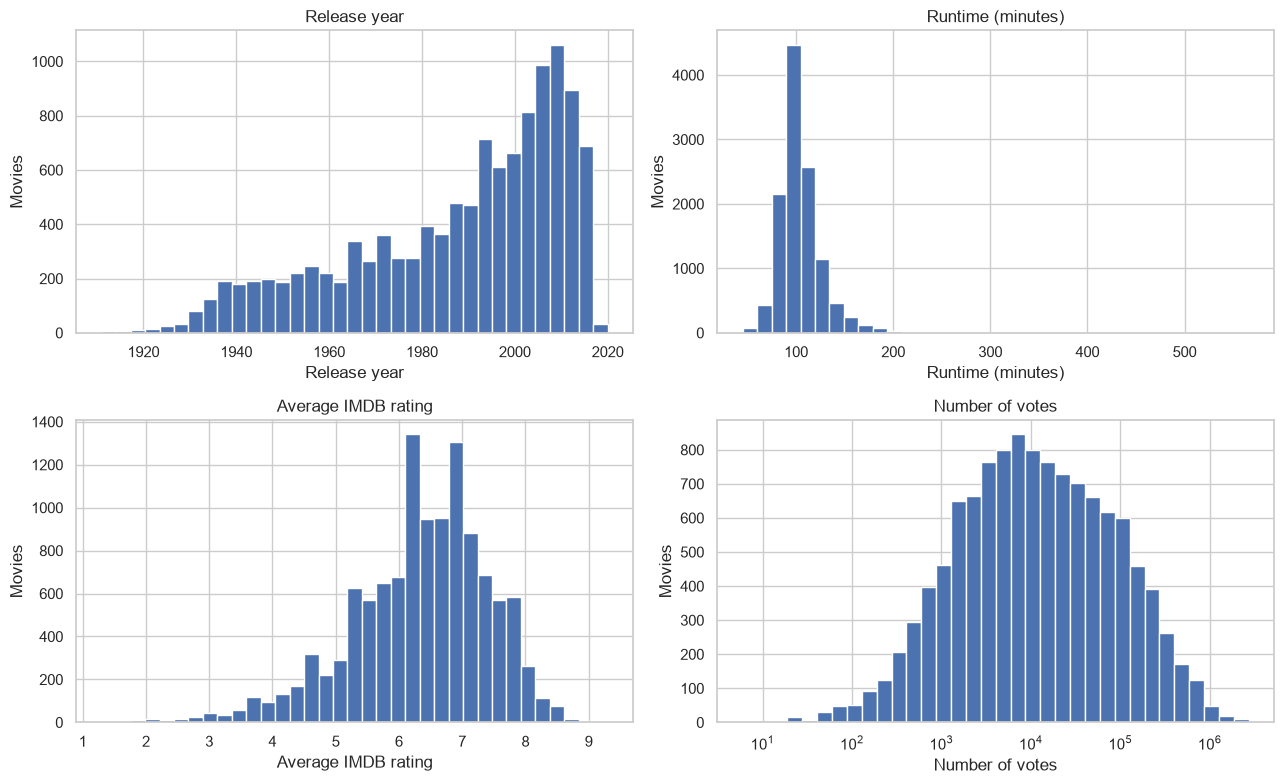

In [3]:
numeric_cols = ["startYear", "runtimeMinutes", "averageRating", "numVotes"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col, label in zip(axes.flat, numeric_cols, ["Release year", "Runtime (minutes)", "Average IMDB rating", "Number of votes"]):
    x = df[col].dropna()
    if col == "numVotes":
        x = x[x > 0]
        bins = np.logspace(np.log10(x.min()), np.log10(x.max()), 35)
        ax.hist(x, bins=bins, edgecolor="white")
        ax.set_xscale("log")
    else:
        ax.hist(x, bins=35, edgecolor="white")
    ax.set(title=label, xlabel=label, ylabel="Movies")
plt.tight_layout(); plt.show()

### 4. Ratings by genre

I'm comparing the rating distributions across genres to see how they differ. Some movies appear in multiple groups because the labels overlap. This is descriptive analysis only; I'm not using rating to predict genre or assuming genre is what caused a rating difference.

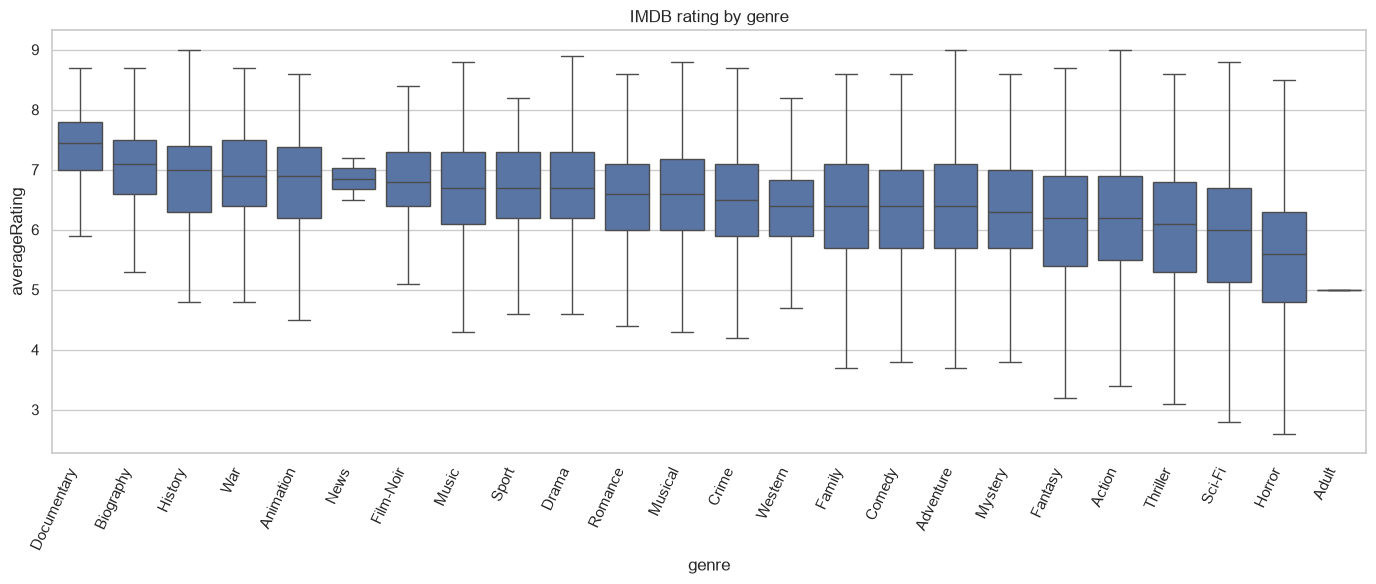

In [4]:
rating_by_genre = df.melt(id_vars="averageRating", value_vars=genres, var_name="genre", value_name="present")
rating_by_genre = rating_by_genre.loc[rating_by_genre["present"] == 1].dropna(subset=["averageRating"])
order = rating_by_genre.groupby("genre")["averageRating"].median().sort_values(ascending=False).index
plt.figure(figsize=(max(12, len(genres)*0.58), 6))
sns.boxplot(data=rating_by_genre, x="genre", y="averageRating", order=order, showfliers=False)
plt.xticks(rotation=65, ha="right"); plt.title("IMDB rating by genre"); plt.tight_layout(); plt.show()

### 5. Vote filter

I'm going with a **100-vote minimum**. I want to screen out movies with almost no rating activity without tossing out a meaningful chunk of the training data. This is intentionally a light filter, and I'll apply the same cutoff in Notebooks 2 and 3.

In [5]:
MIN_VOTES = 100
removed = (df["numVotes"].isna() | (df["numVotes"] < MIN_VOTES))
filter_table = (df.assign(removed=removed).groupby("split", dropna=False)
                .agg(total=("removed", "size"), dropped=("removed", "sum")))
filter_table["retained"] = filter_table["total"] - filter_table["dropped"]
filter_table["pct_dropped"] = (100*filter_table["dropped"]/filter_table["total"]).round(1)
display(filter_table)
filtered = df.loc[~removed].copy()
print(f"Kept {len(filtered):,} / {len(df):,} movies ({len(filtered)/len(df):.1%}).")

,total,dropped,retained,pct_dropped
split,,,,
test,2360,30,2330,1.3
train,7596,79,7517,1.0
val,1868,20,1848,1.1


Kept 11,695 / 11,824 movies (98.9%).


**Filter check:** The 100-vote cutoff removes **79 train**, **20 validation**, and **30 test** movies. That's **129 out of 11,824** movies, or about **1.1%**. I'm comfortable with that tradeoff. It leaves **11,695 movies** to work with and doesn't shrink the dataset much.

### 6. Genre balance

Next I'm checking the positive count and rate for every genre. The main thing I want to know is which classes have enough examples to train on. Accuracy alone can be misleading with rare classes, so I'll account for imbalance when I tune the models in Notebook 2.

,positive_count,positive_rate_pct
Drama,6131,52.42
Comedy,3533,30.21
Action,2618,22.39
Crime,2501,21.39
Romance,2103,17.98
Horror,2079,17.78
Thriller,2027,17.33
Adventure,1805,15.43
Mystery,1302,11.13
Fantasy,911,7.79


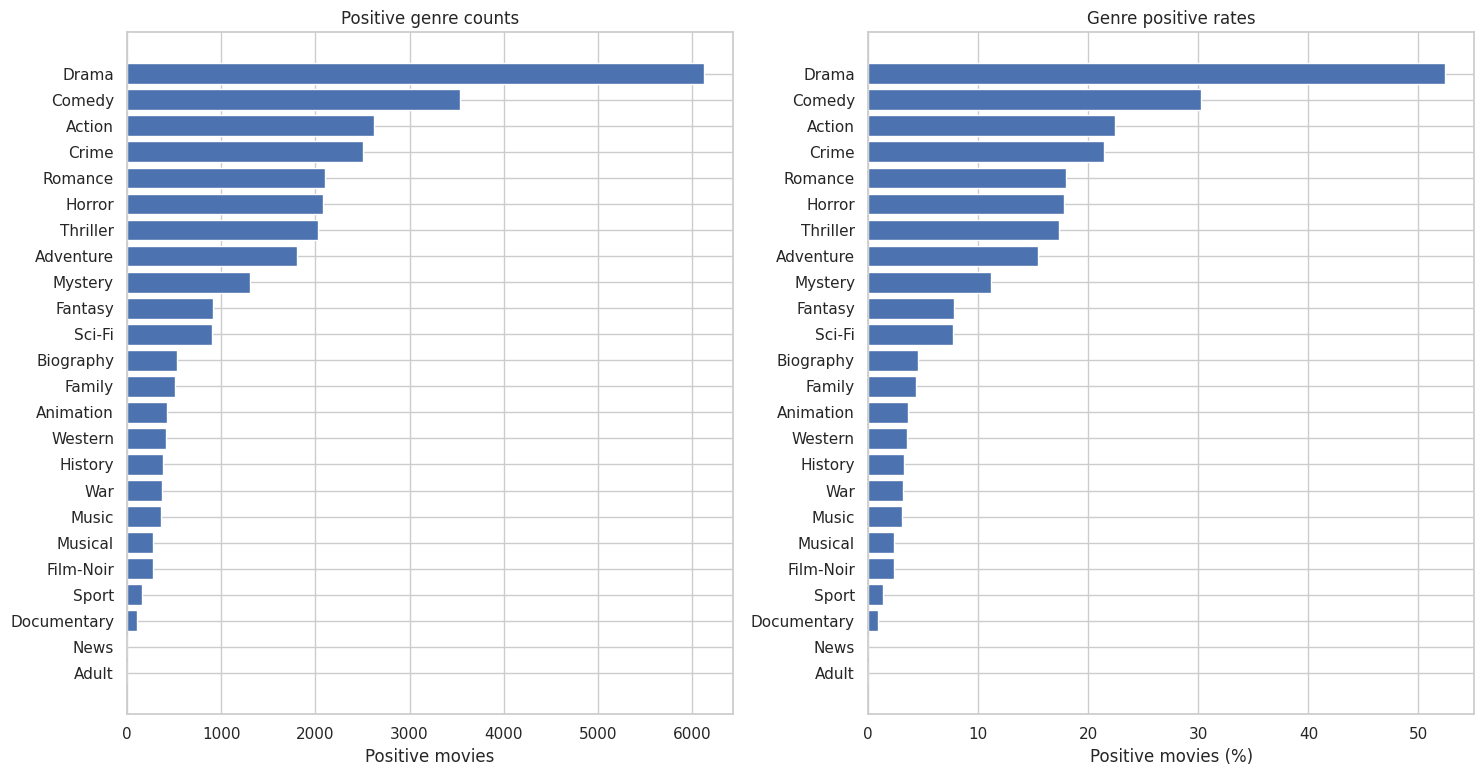

In [6]:
genre_summary = pd.DataFrame({"positive_count":filtered[genres].sum(),
                              "positive_rate_pct":100*filtered[genres].mean()}).sort_values("positive_count", ascending=False)
display(genre_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(15, max(5, len(genres)*0.33)))
axes[0].barh(genre_summary.index[::-1], genre_summary["positive_count"][::-1]); axes[0].set(xlabel="Positive movies", title="Positive genre counts")
axes[1].barh(genre_summary.index[::-1], genre_summary["positive_rate_pct"][::-1]); axes[1].set(xlabel="Positive movies (%)", title="Genre positive rates")
plt.tight_layout(); plt.show()

### 7. Genre overlap

Because movies can have more than one label, I'm checking correlations between the genre columns. This should make the common pairings easier to spot. Correlation here means the labels tend to occur together, not that one genre causes another.

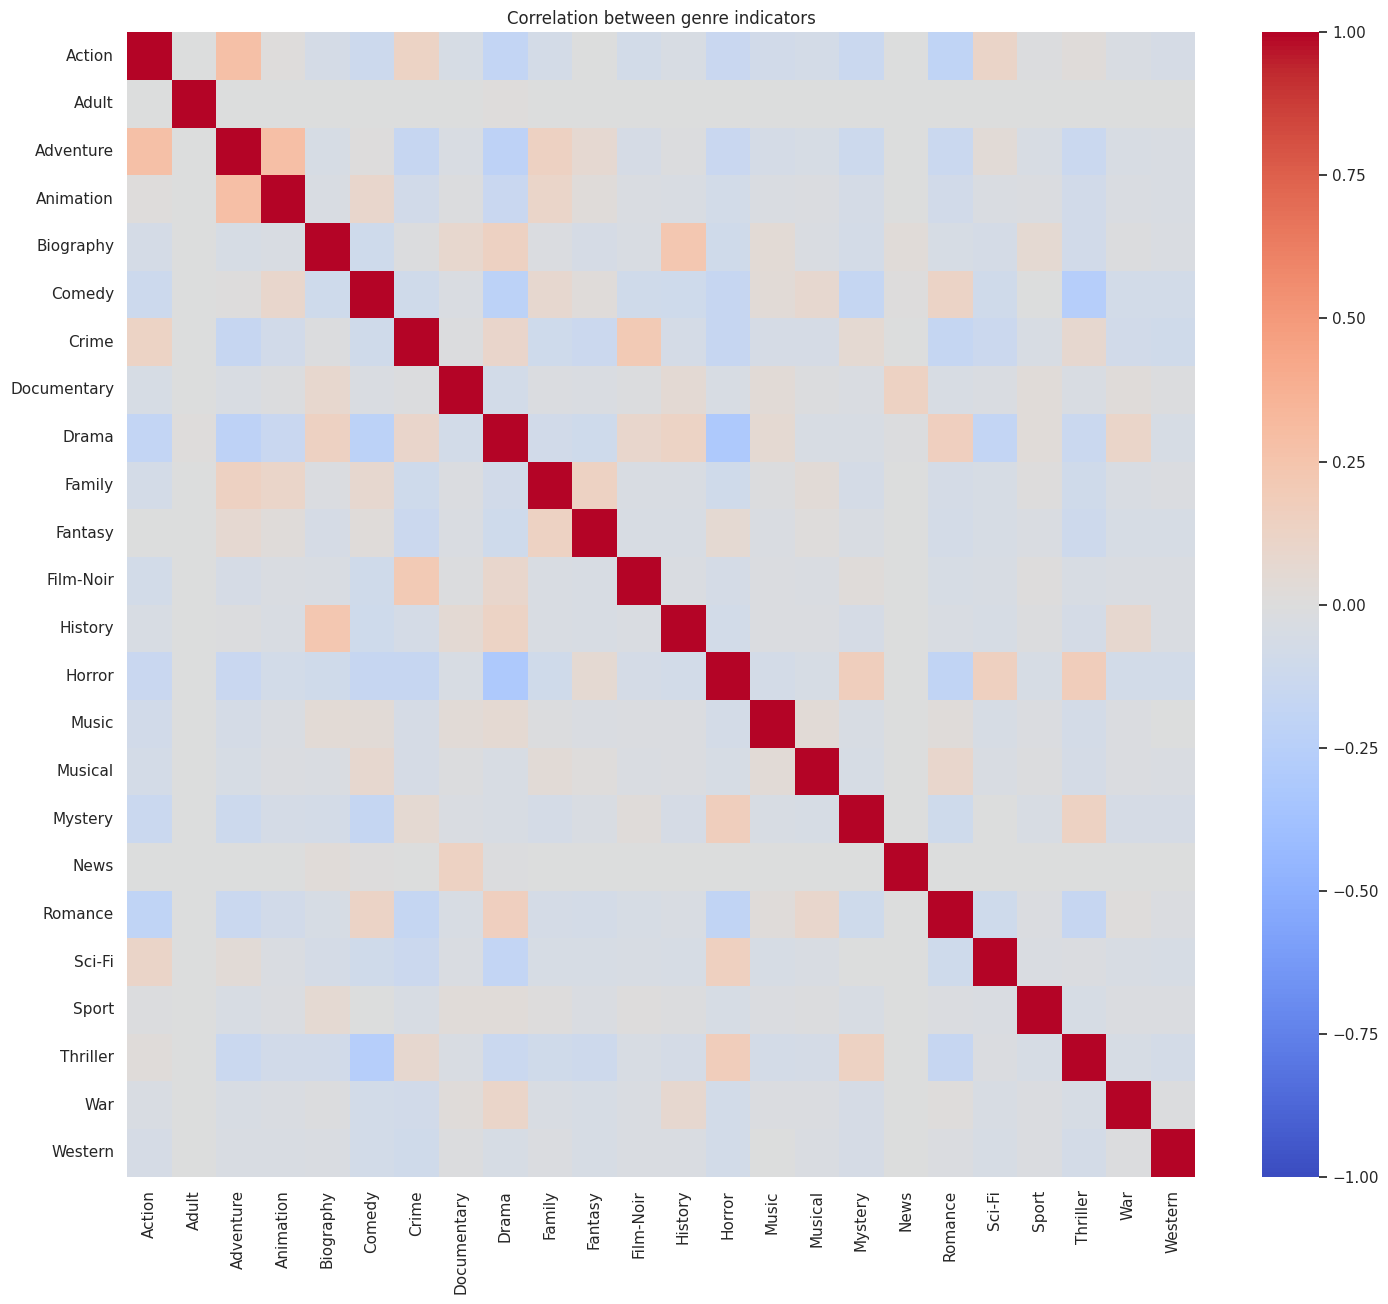

In [7]:
plt.figure(figsize=(max(9, len(genres)*0.62), max(7, len(genres)*0.55)))
sns.heatmap(filtered[genres].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation between genre indicators"); plt.tight_layout(); plt.show()

### 8. Synopsis length

Since the text is the only model input, I need to know how long the synopses are. I'm measuring characters and using whitespace-separated words as a rough token estimate. That's **not** the same as an LLM tokenizer count.

The median synopsis is **3,914 characters** and about **675 words**. The averages are higher—roughly **5,375 characters** and **939 words**—which tells me some long plots are pulling the mean up. That matters for runtime and API usage when I get to embeddings and teacher labeling.

,characters,approx_tokens
mean,5375.4,939.0
median,3914.0,675.0
min,560.0,101.0
max,63959.0,11406.0


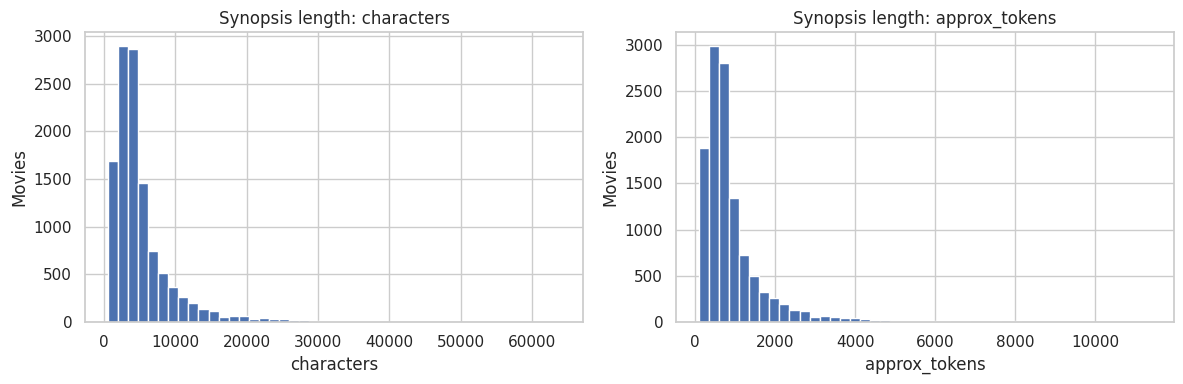

In [8]:
plot_text = filtered["plot_synopsis"].fillna("").astype(str)
lengths = pd.DataFrame({"characters":plot_text.str.len(), "approx_tokens":plot_text.str.split().str.len()})
display(lengths.agg(["mean", "median", "min", "max"]).round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, lengths.columns):
    ax.hist(lengths[column], bins=45); ax.set(title=f"Synopsis length: {column}", xlabel=column, ylabel="Movies")
plt.tight_layout(); plt.show()

### 9. Vocabulary by genre

Now I'm comparing common words overall against words in Action, Comedy, and Horror plots. I'm trying to see whether the genres use noticeably different language before fitting any models.

These are basic frequency counts for EDA, **not TF-IDF modeling**. Common story words can dominate, longer plots have more opportunities to contribute terms, and genre labels overlap. So this is a first look, not evidence that a word will necessarily predict a genre well.

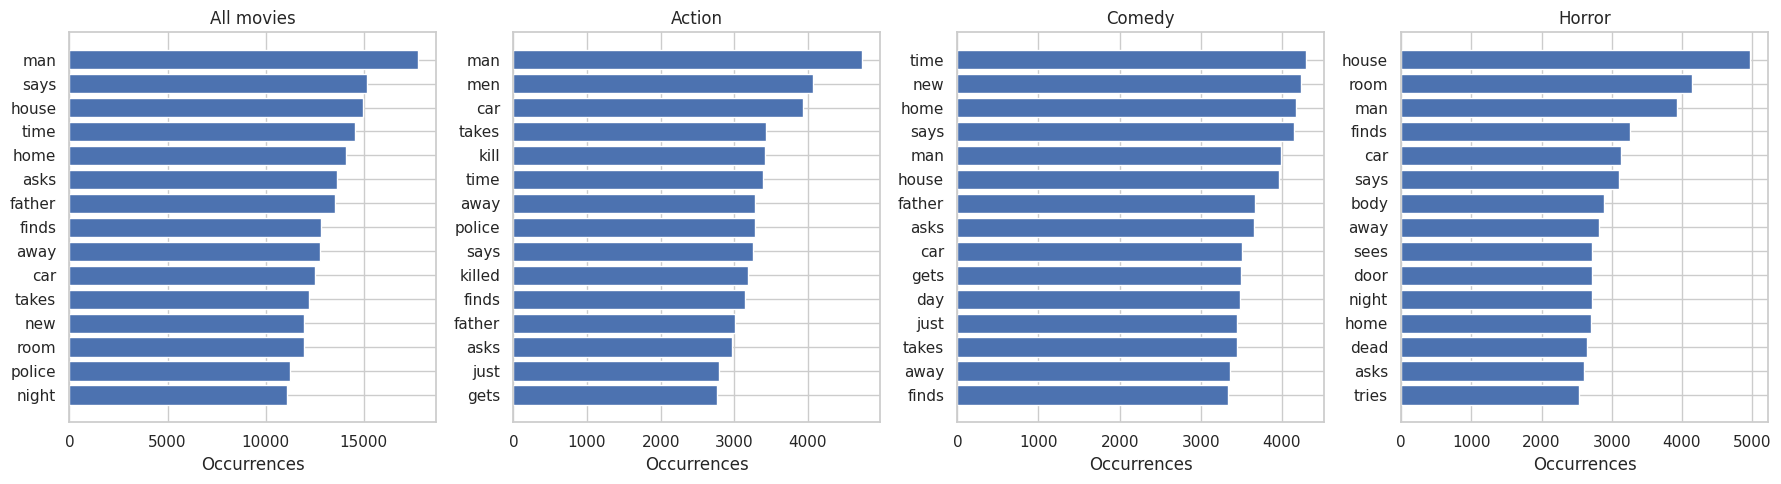

In [9]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
STOPWORDS = set(ENGLISH_STOP_WORDS) | {"film", "movie", "one", "two", "also", "later", "back", "goes", "tells"}
def top_words(texts, n=15):
    words = Counter()
    for plot in texts.fillna("").astype(str):
        words.update(w for w in re.findall(r"[a-z]{3,}", plot.lower()) if w not in STOPWORDS)
    return words.most_common(n)

example_genres = [g for g in ["Action", "Comedy", "Horror"] if g in genres]
if len(example_genres) < 3:
    example_genres += [g for g in genres if g not in example_genres][:3-len(example_genres)]
word_groups = {"All movies": top_words(filtered["plot_synopsis"])}
for genre in example_genres:
    word_groups[genre] = top_words(filtered.loc[filtered[genre] == 1, "plot_synopsis"])
fig, axes = plt.subplots(1, len(word_groups), figsize=(4.5*len(word_groups), 5))
for ax, (group, counts) in zip(axes, word_groups.items()):
    words, vals = zip(*counts) if counts else ([], [])
    ax.barh(list(words)[::-1], list(vals)[::-1]); ax.set_title(group); ax.set_xlabel("Occurrences")
plt.tight_layout(); plt.show()

**How I'm reading these plots:** Words that are common everywhere probably describe movies in general. Words that stand out within one genre could be useful signals, but the modeling results will tell me whether those differences actually help classification.

### 10. Pick genres for Notebook 2

The assignment requires three genres with at least **5% positives in both train+validation and test**. I'm choosing **Action, Comedy, and Horror**. They're familiar, their plot language should be different enough to make the comparison interesting, and all three meet the minimum positive-rate requirement.

I'm only checking eligibility here. The actual feature extraction and classifiers stay in Notebook 2.

In [10]:
train = filtered[filtered["split"].astype(str).str.lower().isin(["train", "val"])]; test = filtered[filtered["split"].astype(str).str.lower() == "test"]
assert len(train) and len(test), "Check split labels; expected train, val and test."
eligibility = pd.DataFrame({"train_val_pct":100*train[genres].mean(), "test_pct":100*test[genres].mean()})
eligibility["eligible"] = (eligibility["train_val_pct"] >= 5) & (eligibility["test_pct"] >= 5)
display(eligibility.sort_values(["eligible", "train_val_pct"], ascending=False).round(2))
print("\nSelected genres (Action, Comedy, Horror):")
display(eligibility.loc[["Action", "Comedy", "Horror"]].round(2))

,train_val_pct,test_pct,eligible
Drama,52.40,52.53,True
Comedy,30.46,29.18,True
Action,22.19,23.18,True
Crime,21.45,21.12,True
Romance,18.01,17.85,True
Horror,17.50,18.88,True
Thriller,17.21,17.81,True
Adventure,15.49,15.19,True
Mystery,11.50,9.66,True
Fantasy,7.75,7.94,True



Selected genres (Action, Comedy, Horror):


,train_val_pct,test_pct,eligible
Action,22.19,23.18,True
Comedy,30.46,29.18,True
Horror,17.50,18.88,True


### Takeaways

I started with **11,824 movies**. After applying the 100-vote cutoff, I have **11,695** left. That's a small amount of filtering, which is what I wanted.

**Drama is the most common genre** at about **52.4%**, followed by **Comedy (30.2%)** and **Action (22.4%)**. Some labels, including Adult and News, barely show up, so they aren't good candidates for this project. I can also see some expected overlap, especially **Animation with Adventure** and **Action with Adventure**.

Synopsis length varies quite a bit, so I'll need to be mindful of processing time and LLM input length. For the three classification targets, I'm sticking with **Action, Comedy, and Horror**. All three clear the assignment's 5% threshold in both splits.

**Next:** I'll compare TF-IDF and sentence embeddings with logistic regression, then see what changes when the training labels come from an LLM instead of IMDB.